## HuggingFace Transformers: API, Models and Fine-Tuning Techniques

### Day 3

In [1]:
import sys
import torch
import transformers
import PIL

print("Python version:", sys.version)
print("Torch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("PIL version:", PIL.__version__)

Python version: 3.14.8 (main, Sep 30 2026, 17:55:09) [Clang 21.0.0 (clang-2100.3.34.2)]
Torch version: 2.14.1
Transformers version: 5.19.0
PIL version: 12.3.0


In [2]:
torch.accelerator.get_memory_info()

(19069190144, 19069665280)

In [5]:
from transformers import pipeline
from accelerate import Accelerator
device = Accelerator().device
device

pipe = pipeline(task="text-classification", device="mps")

pipe.device

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

device(type='mps')

---

### Text to Speech synthesis example

In [3]:
from accelerate import Accelerator
device = Accelerator().device
device

device(type='mps')

In [6]:
# Text to Audio synthesis Example

from transformers import pipeline
#from accelerate import Accelerator
#device = Accelerator().device

#model_name = "Qwen/Qwen3-TTS-12Hz-1.7B-CustomVoice" # Does not work with pipeline() on transformers 5.x
model_name = "suno/bark-small"
#model_name = "hexgrad/Kokoro-82M"
tts = pipeline("text-to-speech", model=model_name)

print("Generating audio from text...")

text = "This is a sample text to demonstrate the text-to-speech synthesis capabilities of the model."

audio = tts(text)
print(audio)
print("-" * 50)

# The Audio can be played directly in a Jupyter Notebook as below:
from IPython.display import Audio
Audio(audio["audio"], rate=audio["sampling_rate"])

Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

Generating audio from text...


[transformers] Passing `generation_config` together with generation-related arguments=({'min_eos_p'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/t

{'audio': array([-0.04159374, -0.04230929, -0.04132403, ...,  0.00154681,
        0.00413734,  0.00456572], shape=(165760,), dtype=float32), 'sampling_rate': 24000}
--------------------------------------------------


In [4]:
from IPython.display import Audio
Audio(audio["audio"], rate=audio["sampling_rate"])

In [5]:
# Suitable for transformers 5.x, using AutoProcessor and BarkModel directly
import torch
from transformers import AutoProcessor, BarkModel
from accelerate import Accelerator

device = Accelerator().device
model_name = "suno/bark-small"
# Load the processor and model explicitly
processor = AutoProcessor.from_pretrained(model_name)
model = BarkModel.from_pretrained(model_name).to(device)

text = "This is a sample text to demonstrate the text-to-speech synthesis capabilities of the model."

# 1. Manually prepare inputs with attention_mask
inputs = processor(text, return_tensors="pt").to(device)

print("Generating audio tokens...")

# 2. Feed attention_mask and define pad_token_id to eliminate the warning
audio_tokens = model.generate(
    input_ids=inputs["input_ids"],
    attention_mask=inputs["attention_mask"],
    pad_token_id=processor.tokenizer.eos_token_id  # Force padding to map to EOS
)
# Convert generated audio tokens back to a numpy array for playback/saving
audio_array = audio_tokens.cpu().numpy().squeeze()

print("Audio generation complete.")

from IPython.display import Audio
Audio(audio_array, rate=16000)  # Assuming a sample rate of 16k

Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'min_eos_p'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating audio tokens...


[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hu

Audio generation complete.


In [7]:
from transformers import pipeline

tts_pipeline = pipeline("text-to-speech", model="facebook/mms-tts-eng")

text_prompt = "The Hugging Face pipeline makes audio generation incredibly easy."
output = tts_pipeline(text_prompt)

from IPython.display import Audio
Audio(output["audio"], rate=output["sampling_rate"])

/Users/chandra/Training/HuggingFace_Transformers/Samples/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

---

### Automatic Speech Recognition (ASR) Example

In [8]:
# Automatic Speech Recognition (ASR) Example

from transformers import pipeline
asr = pipeline("automatic-speech-recognition", model="distil-whisper/distil-small.en")
asr_result = asr("../../harvard.wav")
print(asr_result)
asr_result["text"]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


{'text': ' The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health and zest. A salt pickle tastes fine with ham. Tacos al pastor are my favorite. A zestful food is the hot cross bun.'}


' The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health and zest. A salt pickle tastes fine with ham. Tacos al pastor are my favorite. A zestful food is the hot cross bun.'

In [9]:
# Automatic Speech Recognition (ASR) Example

from transformers import pipeline
asr = pipeline("automatic-speech-recognition", model="distil-whisper/distil-small.en")
asr_result = asr("../../my_voice.wav", return_timestamps=True)
print(asr_result["text"])



Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

 The Linux kernel project is a free and open-source monolithic Unix-like operating system kernel. The Linux kernel was conceived and created in 1991 by Linus Stuwalls for his personal computer, and it has since grown to support a wide variety of computer architectures, including the X86, arm and risk-we instruction sets. The Linux kernel is released under the Gneu General Public Licence version 2 or JPL V2 which allows anyone to view, modify and distribute the source code. The kernel is developed by a large community of developers from around the world with contributions from individuals, companies and organizations. It is used as a foundation for many operating systems. for many operating systems including popular distributions such as Ubuntu, Fedora, and Devian.


In [8]:
asr_result

{'text': ' The Linux kernel project is a free and open-source monolithic Unix-like operating system kernel. The Linux kernel was conceived and created in 1991 by Linus Stuwalls for his personal computer, and it has since grown to support a wide variety of computer architectures, including the X86, arm and risk-we instruction sets. The Linux kernel is released under the Gneu General Public Licence version 2 or JPL V2 which allows anyone to view, modify and distribute the source code. The kernel is developed by a large community of developers from around the world with contributions from individuals, companies and organizations. It is used as a foundation for many operating systems. for many operating systems including popular distributions such as Ubuntu, Fedora, and Devian.',
 'chunks': [{'timestamp': (0.0, 7.0),
   'text': ' The Linux kernel project is a free and open-source monolithic Unix-like operating system kernel.'},
  {'timestamp': (7.0, 16.0),
   'text': ' The Linux kernel was

---

### Text to Image Generation Example

In [9]:
!pip install diffusers

In [1]:
# Text to Image Generation Example
import torch
from diffusers import StableDiffusionPipeline
from accelerate import Accelerator
device = Accelerator().device

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16
)

pipe = pipe.to(device)

prompt = "a photorealistic image of an astronaut riding a horse in a futuristic city, digital art"
result = pipe(prompt)
print(result)
image = result.images[0]
image.save("../astronaut_riding_horse9.png")
image.show()

/Users/chandra/Training/HuggingFace_Transformers/Samples/.venv/lib/python3.14/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

StableDiffusionPipelineOutput(images=[<PIL.Image.Image image mode=RGB size=512x512 at 0x1308516E0>], nsfw_content_detected=[False])


In [2]:
# Text to Image Generation Example
import torch
from diffusers import StableDiffusionPipeline
from accelerate import Accelerator
device = Accelerator().device

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16
)
pipe = pipe.to(device)

prompt = "a photorealistic image of an Indian youth working on a computer"
result = pipe(prompt)
print(result)
image = result.images[0]
image.save("../image3.png")
image.show()

/Users/chandra/Training/HuggingFace_Transformers/Samples/.venv/lib/python3.14/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

StableDiffusionPipelineOutput(images=[<PIL.Image.Image image mode=RGB size=512x512 at 0x1307FF250>], nsfw_content_detected=[False])


In [1]:
from diffusers import DiffusionPipeline
import torch

from accelerate import Accelerator
device = Accelerator().device

#model_name = "Qwen/Qwen-Image"
model_name = "Qwen/Qwen-Image-2.1-Turbo"
pipe = DiffusionPipeline.from_pretrained(model_name, torch_dtype=torch.float16)
pipe = pipe.to(device)

positive_magic = {
    "en": ", Ultra HD, 4K, cinematic composition.", # for english prompt
    "zh": ", 超清，4K，电影级构图." # for chinese prompt
}

# Generate image
prompt = '''
A coffee shop entrance features a chalkboard sign reading 
"Qwen Coffee 😊 $2 per cup," with a neon light beside it 
displaying "通义千问". Next to it hangs a poster showing a beautiful 
Chinese woman, and beneath the poster is 
written "π≈3.1415926-53589793-23846264-33832795-02384197". 
Ultra HD, 4K, cinematic composition'''

negative_prompt = " " # using an empty string if you do not have specific concept to remove


# Generate with different aspect ratios
aspect_ratios = {
    "1:1": (1328, 1328),
    "16:9": (1664, 928),
    "9:16": (928, 1664),
    "4:3": (1472, 1140),
    "3:4": (1140, 1472),
    "3:2": (1584, 1056),
    "2:3": (1056, 1584),
}

width, height = aspect_ratios["16:9"]

image = pipe(
    prompt=prompt + positive_magic["en"],
    negative_prompt=negative_prompt,
    width=width,
    height=height,
    num_inference_steps=50,
    true_cfg_scale=4.0,
    generator=torch.Generator(device=device).manual_seed(42)
).images[0]

image.save("../qwen_image_example.png")


/Users/chandra/Training/HuggingFace_Transformers/Samples/.venv/lib/python3.14/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

KeyboardInterrupt: 

##### Image Segmentation using Vision Transformers (ViT)

Fetching image...
Image fetched successfully.


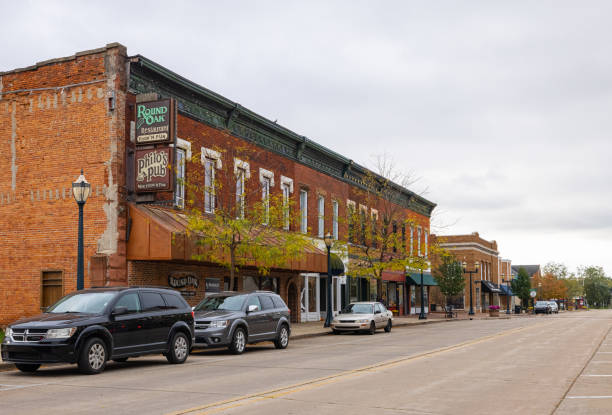

In [1]:
from PIL import Image
import requests

print("Fetching image...")
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/segmentation_input.jpg"
image = Image.open(requests.get(url, stream=True).raw)
print("Image fetched successfully.")
image

In [ ]:
print(type(image))

In [2]:
from transformers import pipeline
semantic_segmentation = pipeline("image-segmentation", 
                                 "nvidia/segformer-b1-finetuned-cityscapes-1024-1024",
                                 use_fast=True)

results = semantic_segmentation(image)
results

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[{'score': None,
  'label': 'road',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'sidewalk',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'building',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'wall',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'pole',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'traffic sign',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'vegetation',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'terrain',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'sky',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=612x415>}]

In [3]:
results[-1]

{'score': None,
 'label': 'car',
 'mask': <PIL.Image.Image image mode=L size=612x415>}

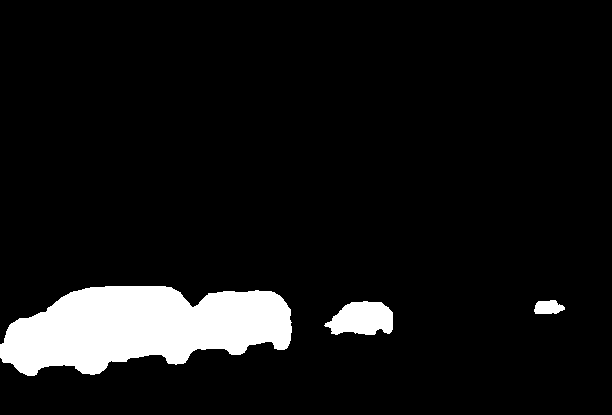

In [4]:
results[-1]["mask"]

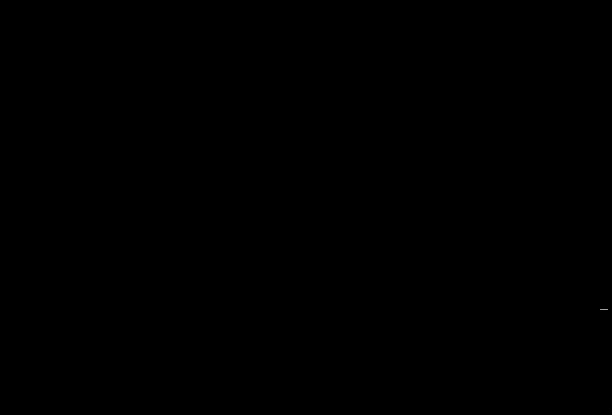

In [8]:
Image.composite(image, results[-3]["mask"], results[-3]["mask"])

--- 

##### Image Classification using Vision Transformers (ViT)

In [ ]:
!pip install matplotlib

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

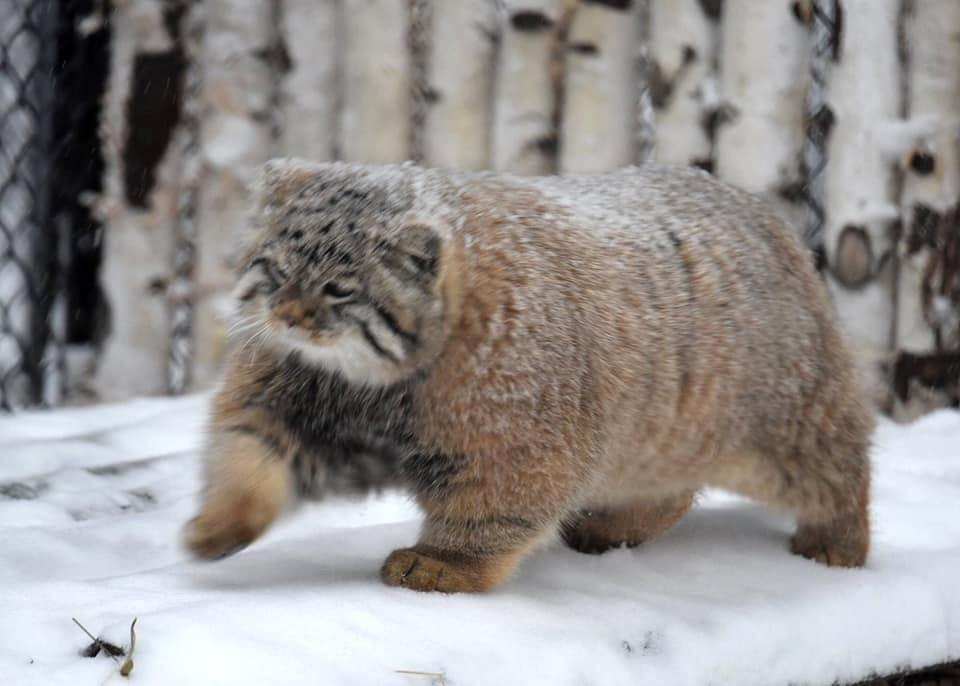

In [9]:
from transformers import pipeline
from PIL import Image
import requests

import matplotlib.pyplot as plt

# Load image classification pipeline
classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224")

# Load a sample image
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
response = requests.get(url, stream=True).raw
image = Image.open(response)

image

In [10]:

# Classify
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")


lynx, catamount: 0.433
cougar, puma, catamount, mountain lion, painter, panther, Felis concolor: 0.035
snow leopard, ounce, Panthera uncia: 0.032
Egyptian cat: 0.024
tiger cat: 0.023


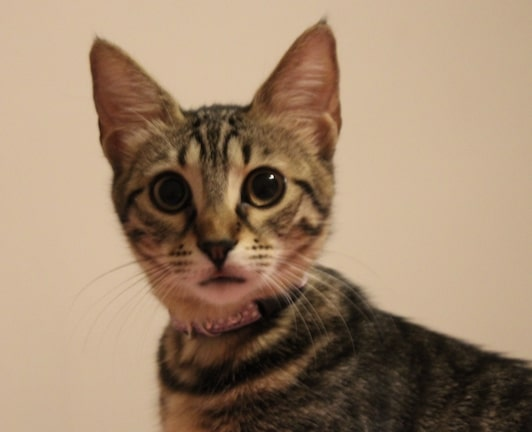

In [17]:
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/cat.jpg"
image = Image.open(requests.get(url, stream=True).raw)
image

In [12]:
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

tabby, tabby cat: 0.471
Egyptian cat: 0.399
tiger cat: 0.124
lynx, catamount: 0.003
Siamese cat, Siamese: 0.000


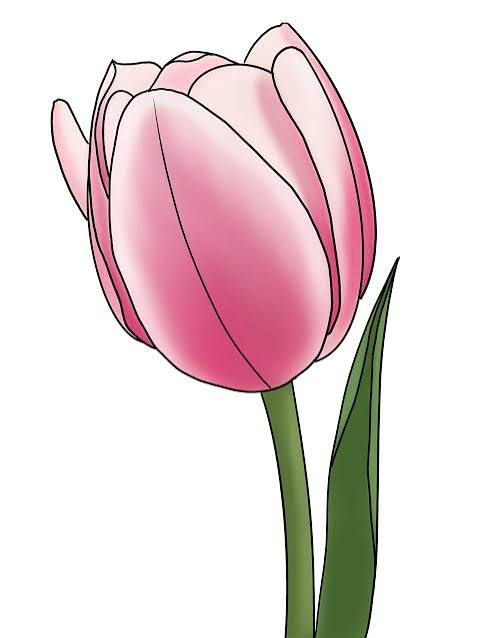

In [13]:
image = Image.open("../../tulip2.jpeg")
image

In [14]:
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

vase: 0.328
daisy: 0.278
pot, flowerpot: 0.020
pinwheel: 0.009
goblet: 0.007


In [15]:

print("---")
# Try with your own images
image = Image.open("../../tulip2.jpeg")
results = classifier(image)
for result in results[:5]:
    print(f"{result['label']}: {result['score']:.3f}")

---
vase: 0.328
daisy: 0.278
pot, flowerpot: 0.020
pinwheel: 0.009
goblet: 0.007


In [5]:
!pip install sentencepiece

  Using cached sentencepiece-0.2.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (33 kB)
Using cached sentencepiece-0.2.2-cp314-cp314-macosx_11_0_arm64.whl (1.3 MB)


In [2]:
!pip install protobuf

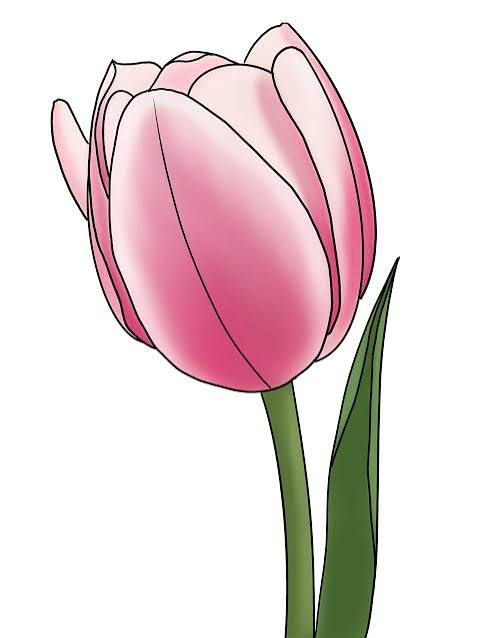

In [15]:
image

In [18]:
from transformers import pipeline
from PIL import Image
import requests

# load pipe
image_classifier = pipeline(task="zero-shot-image-classification", 
                            model="google/siglip-base-patch16-224")

# load image
#url = 'http://images.cocodataset.org/val2017/000000039769.jpg'
#image = Image.open(requests.get(url, stream=True).raw)

cat_labels = ["cow", "horse", "cat", "tiger", "cheetah"]

# inference
outputs = image_classifier(image, candidate_labels=cat_labels)

outputs = [{"score": round(output["score"], 4), "label": output["label"] } for output in outputs]
print(outputs)


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

[{'score': 0.0518, 'label': 'cat'}, {'score': 0.0009, 'label': 'tiger'}, {'score': 0.0, 'label': 'cheetah'}, {'score': 0.0, 'label': 'cow'}, {'score': 0.0, 'label': 'horse'}]


In [18]:
# Load a sample image
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg"
response = requests.get(url, stream=True).raw
image = Image.open(response)

outputs = image_classifier(image, candidate_labels=["dog", "cow", "cheetah", "puma", "cat"])

outputs = [{"score": round(output["score"], 4), "label": output["label"] } for output in outputs]
print(outputs)


[{'score': 0.0008, 'label': 'cat'}, {'score': 0.0004, 'label': 'puma'}, {'score': 0.0, 'label': 'cheetah'}, {'score': 0.0, 'label': 'dog'}, {'score': 0.0, 'label': 'cow'}]


In [20]:
image_classifier.model

SiglipModel(
  (text_model): SiglipTextModel(
    (embeddings): SiglipTextEmbeddings(
      (token_embedding): Embedding(32000, 768)
      (position_embedding): Embedding(64, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
          (mlp): SiglipMLP(
            (activation_fn): GELUTanh()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=30

---

#### Image Enhancement

(532, 432)


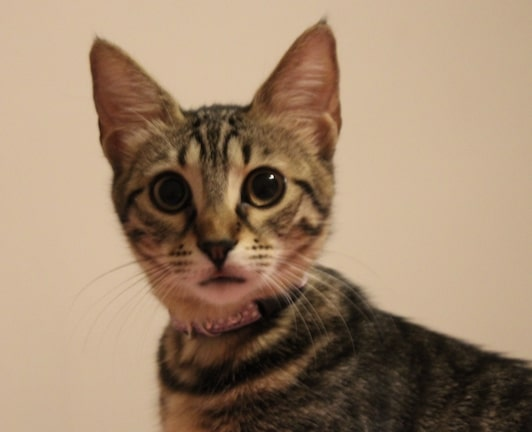

In [21]:
from PIL import Image
import requests

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/cat.jpg"
image = Image.open(requests.get(url, stream=True).raw)

print(image.size)
image

In [22]:
from transformers import pipeline
pipe = pipeline(task="image-to-image", model="caidas/swin2SR-lightweight-x2-64")

upscaled = pipe(image)
print(upscaled.size)
upscaled

KeyError: 'The task image-to-image has been removed from transformers. For image generation tasks, please use 🤗 Diffusers instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

(2160, 1776)


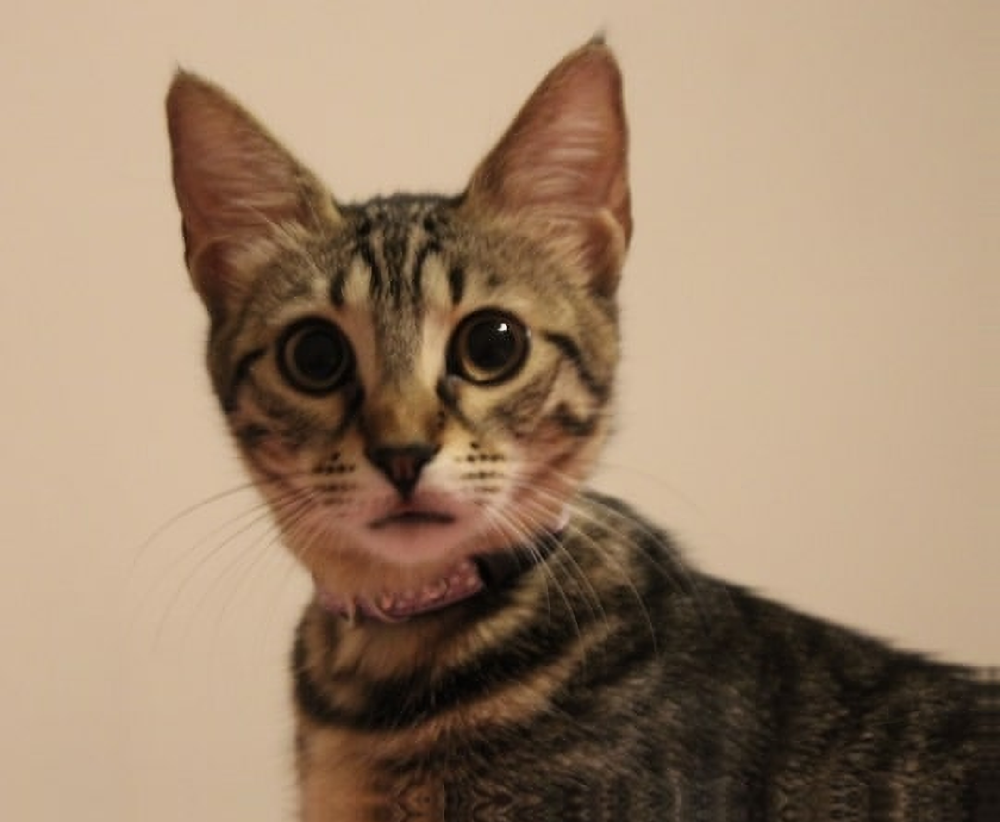

In [18]:
upscaled = pipe(upscaled)
print(upscaled.size)
upscaled

In [ ]:
import requests
from PIL import Image
from io import BytesIO
from diffusers import StableDiffusionUpscalePipeline
import torch

# load model and scheduler
model_id = "stabilityai/stable-diffusion-x4-upscaler"
pipeline = StableDiffusionUpscalePipeline.from_pretrained(
    model_id, variant="fp16", torch_dtype=torch.float16
)
pipeline = pipeline.to("mps")

# let's download an  image
#url = "https://huggingface.co/datasets/hf-internal-testing/diffusers-images/resolve/main/sd2-upscale/low_res_cat.png"
#response = requests.get(url)
#low_res_img = Image.open(BytesIO(response.content)).convert("RGB")
#low_res_img = low_res_img.resize((128, 128))

prompt = "a white cat"

upscaled_image = pipeline(prompt=prompt, image=image).images[0]
upscaled_image.save("upsampled_cat.png")

In [22]:
from transformers import AutoModelForImageClassification
model = AutoModelForImageClassification.from_pretrained("google/vit-base-patch16-224")
model

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear

In [23]:
model = AutoModelForImageClassification.from_pretrained("google/siglip-base-patch16-224")
model

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipForImageClassification LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     | 
-------------------------------------------------------------+------------+-
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight  

SiglipForImageClassification(
  (vision_model): SiglipVisionModel(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), padding=valid)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
          (mlp): SiglipMLP(
            (activation_fn): GELUTanh()
            (fc1): Linear(in_features=768,

---

#### Working with ```datasets```

In [24]:
from datasets import load_dataset

In [26]:
datasets = load_dataset("ethz/food101")
datasets

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 75750
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 25250
    })
})

In [27]:
datasets.keys()

dict_keys(['train', 'validation'])

In [29]:
train_dataset = datasets["train"]
train_dataset

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [30]:
train_dataset.column_names

['image', 'label']

In [31]:
train_dataset[0]

{'image': <PIL.Image.Image image mode=RGB size=384x512>, 'label': 6}

In [35]:
train_dataset.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

In [36]:
len(train_dataset.features["label"].names)

101

In [38]:
train_dataset.features["label"].num_classes

101

In [39]:
classes = train_dataset.features["label"]
classes

ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich', 'macaroni_and_cheese', 'mac

In [45]:
print(classes.num_classes)
print(classes.names)
print(classes.str2int(classes.names))
print(classes.str2int("beet_salad"))
print(classes.int2str(6))

101
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich', 'macaroni_and_cheese', 'macarons', 'miso

In [46]:
train_dataset.num_rows

75750

eggs_benedict


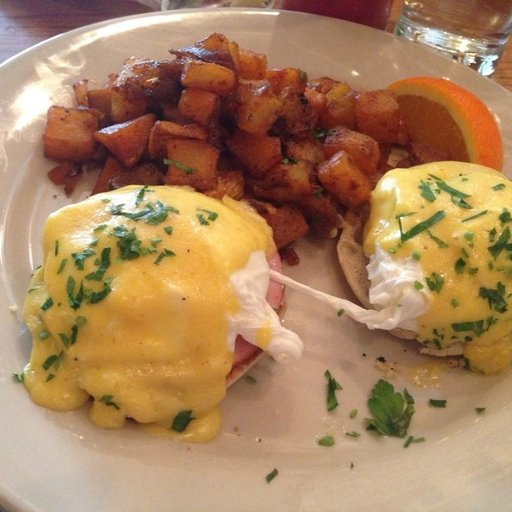

In [52]:
def get_dataset_item(dataset, index):
    image = dataset[index]["image"]
    label = dataset[index]["label"]
    return image, dataset.features["label"].int2str(label)

image, label = get_dataset_item(train_dataset, 8585)
print(label)
image

In [29]:
dataset.column_names

{'train': ['image', 'label'], 'validation': ['image', 'label']}

In [30]:
dataset["train"].column_names

['image', 'label']

In [32]:
d = dataset["train"]
d

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [33]:
d.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', '

In [34]:
d.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

In [35]:
d.num_rows, d.num_columns

(75750, 2)

In [36]:
len(d.features["label"].names) # Number of classes in the dataset

101

In [37]:
lbl = d.features["label"]
lbl.num_classes

101

In [46]:
d.features["label"].num_classes

101

In [40]:
d.features["label"].names[2]

'baklava'

In [41]:
lbl.str2int("baklava")

2

In [45]:
lbl.int2str(2)
d.features["label"].int2str(50)

'grilled_salmon'

In [ ]:
dataset.keys() # Identify the splits in the dataset

In [46]:
v = dataset["validation"]

In [47]:
v.column_names

['image', 'label']

In [48]:
v.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', '

In [49]:
v.num_rows

25250

In [50]:
v.features["label"].num_classes  # Fetch the number of classes in the label feature

101

In [51]:
train_dataset = dataset["train"]
train_dataset

Dataset({
    features: ['image', 'label'],
    num_rows: 75750
})

In [52]:
train_dataset[0]

{'image': <PIL.Image.Image image mode=RGB size=384x512>, 'label': 6}

In [55]:
train_dataset.features["label"].int2str(6)

'beignets'

In [60]:
train_dataset.features["label"].names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

Idx: 9919 , Label: chocolate_cake


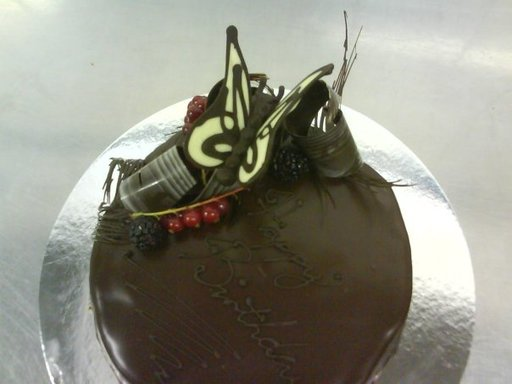

In [60]:
from random import randint

idx = randint(0, len(train_dataset) - 1)

print("Idx:", idx, ", Label:", train_dataset.features["label"].int2str(train_dataset[idx]["label"]))
train_dataset[idx]["image"]

In [ ]:
train_dataset.features["label"].int2str(train_dataset[0]["label"])

In [72]:
dataset2 = load_dataset("ariG23498/flickr8k")
dataset2

DatasetDict({
    train: Dataset({
        features: ['image', 'caption'],
        num_rows: 40455
    })
})

In [53]:
from datasets import Dataset

dataset = Dataset.from_csv("./reviews_simple.csv")
dataset

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 4
})

In [55]:
dataset = Dataset.from_dict({
    "text": ["I love this movie!", "I hate this movie!"],
    "label": [1, 0]
})

dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 2
})

In [56]:
dataset = Dataset.from_list([
    {"text": "I love this movie!", "label": 1},
    {"text": "I hate this movie!", "label": 0}
])
dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 2
})

In [57]:
from datasets import load_dataset

dataset = load_dataset("csv", data_files="reviews_simple.csv")
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4
    })
})

https://files.chandrashekar.info/chessman.zip

In [58]:
from datasets import load_dataset

chess_dataset = load_dataset("../../Chessman-image-dataset/Chess")
chess_dataset

Resolving data files:   0%|          | 0/556 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 556
    })
})

In [64]:
from datasets import DatasetDict, load_dataset

chess_dataset = load_dataset("../../Chessman-image-dataset/Chess")

chess_dataset = chess_dataset["train"].train_test_split(test_size=0.2)

train_dataset = chess_dataset["train"]

validate_test_dataset = chess_dataset["test"].train_test_split(test_size=0.5)
validate_test_dataset

dataset = DatasetDict({
    "train": train_dataset,
    "validation": validate_test_dataset["train"],
    "test": validate_test_dataset["test"]
})
dataset

Resolving data files:   0%|          | 0/556 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 444
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
})

In [77]:
dataset_dict = dataset2["train"].train_test_split(test_size=0.15, seed=42)
ndataset_dict = dataset_dict["train"].train_test_split(test_size=0.1, seed=42)

train_dataset = ndataset_dict["train"]
validation_dataset = ndataset_dict["test"]
test_dataset = dataset_dict["test"]

dataset_dict = {
    "train": train_dataset,
    "validation": validation_dataset,
    "test": test_dataset
}
dataset_dict

{'train': Dataset({
     features: ['image', 'caption'],
     num_rows: 30947
 }),
 'validation': Dataset({
     features: ['image', 'caption'],
     num_rows: 3439
 }),
 'test': Dataset({
     features: ['image', 'caption'],
     num_rows: 6069
 })}

In [66]:
dataset2["train"].features

{'image': Image(mode=None, decode=True), 'caption': Value('string')}

In [ ]:
from datasets import Dataset

dataset = Dataset.from_dict(
          {"label": [0, 1, 2], 
           "image": ["img1.png", "img2.png", "img3.png"]}
)

dataset = Dataset.from_csv()

Dataset({
    features: ['label', 'image'],
    num_rows: 3
})

In [63]:
from datasets import Dataset

d = Dataset.from_csv("reviews_simple.csv")
d

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 4
})

In [76]:
from datasets import Value, ClassLabel
d.features["label"] = ClassLabel(names=["negative", "positive"])
d.features.update({"label": ClassLabel(names=["negative", "positive"])})
d.features

{'text': Value('large_string'), 'label': Value('int64')}

In [77]:
d = load_dataset("csv", data_files="reviews_simple.csv")
d

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4
    })
})

In [ ]:
load_dataset?

Signature:
load_dataset(
    path: str,
    name: Optional[str] = None,
    data_dir: Optional[str] = None,
    data_files: Union[str, collections.abc.Sequence[str], collections.abc.Mapping[str, Union[str, collections.abc.Sequence[str]]], NoneType] = None,
    split: Union[str, datasets.splits.Split, list[str], list[datasets.splits.Split], NoneType] = None,
    cache_dir: Optional[str] = None,
    features: Optional[datasets.features.features.Features] = None,
    download_config: Optional[datasets.download.download_config.DownloadConfig] = None,
    download_mode: Union[datasets.download.download_manager.DownloadMode, str, NoneType] = None,
    verification_mode: Union[datasets.utils.info_utils.VerificationMode, str, NoneType] = None,
    keep_in_memory: Optional[bool] = None,
    save_infos: bool = False,
    revision: Union[datasets.utils.version.Version, str, NoneType] = None,
    token: Union[bool, str, NoneType] = None,
    streaming: bool = False,
    num_proc: Optional[int] = N

In [80]:
d["train"].features

{'text': Value('large_string'), 'label': Value('int64')}

In [81]:
from datasets import load_dataset

d = load_dataset("../../ChessMan-image-dataset/Chess")
d

Resolving data files:   0%|          | 0/555 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 555
    })
})

In [82]:
train_dataset = d["train"]
train_dataset.features

{'image': Image(mode=None, decode=True),
 'label': ClassLabel(names=['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook'])}

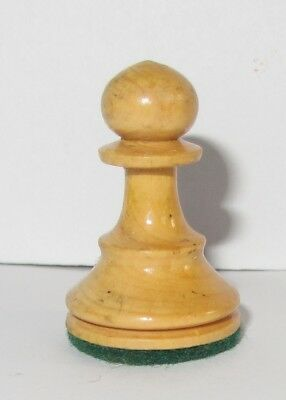

In [95]:
train_dataset[350]["image"]

In [99]:
split_dataset = train_dataset.train_test_split(test_size=0.2)
train_dataset = split_dataset["train"]
test_dataset = split_dataset["test"]

test_validation_split = test_dataset.train_test_split(test_size=0.5)
test_dataset = test_validation_split["train"]
validation_dataset = test_validation_split["test"]

dataset = {
    "train": train_dataset,
    "test": test_dataset,
    "validation": validation_dataset
}
dataset

{'train': Dataset({
     features: ['image', 'label'],
     num_rows: 444
 }),
 'test': Dataset({
     features: ['image', 'label'],
     num_rows: 55
 }),
 'validation': Dataset({
     features: ['image', 'label'],
     num_rows: 56
 })}

---
## Model Fine-tuning examples

---

#### Finetuning ModernBERT with custom dataset

In [65]:
from datasets import load_dataset

# Dataset id from huggingface.co/dataset
dataset_id = "cornell-movie-review-data/rotten_tomatoes"

# Load raw dataset
raw_dataset = load_dataset(dataset_id)

print(f"Train dataset size: {len(raw_dataset['train'])}")
print(f"Test dataset size: {len(raw_dataset['test'])}")

Train dataset size: 8530
Test dataset size: 1066


In [11]:
raw_dataset["train"].features

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

In [15]:
from random import randrange

random_id = randrange(len(raw_dataset['train']))
raw_dataset['train'][random_id]


{'text': "more vaudeville show than well-constructed narrative , but on those terms it's inoffensive and actually rather sweet .",
 'label': 1}

In [16]:
from transformers import AutoTokenizer

# Model id to load the tokenizer
model_id = "answerdotai/ModernBERT-base"

# Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.model_max_length = 512 # set model_max_length to 512 as prompts are not longer than 1024 tokens

# Tokenize helper function
def tokenize(batch):
    return tokenizer(batch['text'], padding='max_length', truncation=True, return_tensors="pt")

# Tokenize dataset
raw_dataset =  raw_dataset.rename_column("label", "labels") # to match Trainer
tokenized_dataset = raw_dataset.map(tokenize, batched=True,remove_columns=["text"])

print(tokenized_dataset["train"].features.keys())
# dict_keys(['input_ids', 'attention_mask','labels'])

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

dict_keys(['labels', 'input_ids', 'attention_mask'])


In [17]:
from transformers import AutoModelForSequenceClassification

# Model id to load the tokenizer
model_id = "answerdotai/ModernBERT-base"

# Prepare model labels - useful for inference
labels = tokenized_dataset["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

# Download the model from huggingface.co/models
model = AutoModelForSequenceClassification.from_pretrained(
    model_id, num_labels=num_labels, label2id=label2id, id2label=id2label,
)

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
!pip install scikit-learn

In [19]:
import numpy as np
from sklearn.metrics import f1_score

# Metric helper method
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    score = f1_score(
            labels, predictions, labels=labels, pos_label=1, average="weighted"
        )
    return {"f1": float(score) if score == 1 else score}

In [20]:
from transformers import Trainer, TrainingArguments

# Define training args
training_args = TrainingArguments(
    output_dir= "modernbert-rotten-tomatoes",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
		num_train_epochs=5,
    bf16=True, # bfloat16 training 
    optim="adamw_torch_fused", # improved optimizer 
    # logging & evaluation strategies
    logging_strategy="steps",
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # push to hub parameters
    #report_to="tensorboard",
    push_to_hub=False,

)

# Create a Trainer instance
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    compute_metrics=compute_metrics,
)

In [ ]:
# Start training
trainer.train()

Epoch,Training Loss,Validation Loss


In [ ]:
# Save processor and create model card
tokenizer.save_pretrained("modernbert-rotten-tomatoes")
trainer.create_model_card()
trainer.push_to_hub()

---

### Finetuning an Image Classifier (ViT) with custom Image dataset

#### The `Trainer` API

`Trainer` is a complete training and evaluation loop for Transformers’ PyTorch models. Plug a model, preprocessor, dataset, and training arguments into `Trainer` and let it handle the rest to start training faster.

The Trainer simplifies the overhead of implementing our training loop for our training workflow using PyTorch models.

Trainer contains all the necessary components of a training loop.

 1. calculate the loss from a training step
 2. calculate the gradients with the backward method
 3. update the weights based on the gradients
 4. repeat until the predetermined number of epochs is reached

Manually coding this training loop everytime can be inconvenient or a barrier if you’re just getting started with machine learning. Trainer abstracts this process, allowing you to focus on the model, dataset, and training design choices.

The training hyperparameters and options can be easily configured your using `TrainingArguments` which supports many features such as distributed training, torch.compile, mixed precision training, and saving the model to the Hub.

The `TrainingArguments` takes around *120* parameters for configuration!


#### Analyze the custom dataset (ChessMan)

This dataset can be downloaded from https://files.chandrashekar.info/chessman.zip


In [71]:
##### Step 1: Load your custom dataset

from datasets import load_dataset

dataset = load_dataset("../../Chessman-image-dataset/Chess")
dataset

Resolving data files:   0%|          | 0/556 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 556
    })
})

In [101]:
dataset['train'].features["label"].names

['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook']

In [102]:
dataset["train"].features["label"].num_classes

6

In [103]:
lbl = dataset["train"].features["label"]
lbl

ClassLabel(names=['Bishop', 'King', 'Knight', 'Pawn', 'Queen', 'Rook'])

In [104]:
lbl.str2int(lbl.names)

[0, 1, 2, 3, 4, 5]

In [105]:
lbl.int2str([3, 2, 1, 1, 0])

['Pawn', 'Knight', 'King', 'King', 'Bishop']

In [73]:
##### Step 2: Split the dataset into training, validation and testing sets

# Split the dataset into training and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_test

train_dataset = train_test["train"]
validate_test_dataset = train_test["test"].train_test_split(test_size=0.5)

dataset = DatasetDict({
    "train": train_dataset,
    "validation": validate_test_dataset["train"],
    "test": validate_test_dataset["test"]
})
dataset


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 444
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 56
    })
})

In [74]:
num_classes = dataset["train"].features["label"].num_classes
num_classes

6

In [75]:
##### Step 3: Use a pretrained model

checkpoint = "google/vit-base-patch16-224-in21k"

In [76]:
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained(
    checkpoint, num_labels=num_classes
)
print(f"Total parameters: {model.num_parameters()}")
print(f"Trainable parameters: {model.num_parameters(only_trainable=True)}")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 85803270
Trainable parameters: 85803270


In [78]:
for name, parameters in model.named_parameters():
    print(name, parameters.shape)

vit.embeddings.cls_token torch.Size([1, 1, 768])
vit.embeddings.position_embeddings torch.Size([1, 197, 768])
vit.embeddings.patch_embeddings.projection.weight torch.Size([768, 3, 16, 16])
vit.embeddings.patch_embeddings.projection.bias torch.Size([768])
vit.layers.0.attention.q_proj.weight torch.Size([768, 768])
vit.layers.0.attention.q_proj.bias torch.Size([768])
vit.layers.0.attention.k_proj.weight torch.Size([768, 768])
vit.layers.0.attention.k_proj.bias torch.Size([768])
vit.layers.0.attention.v_proj.weight torch.Size([768, 768])
vit.layers.0.attention.v_proj.bias torch.Size([768])
vit.layers.0.attention.o_proj.weight torch.Size([768, 768])
vit.layers.0.attention.o_proj.bias torch.Size([768])
vit.layers.0.layernorm_before.weight torch.Size([768])
vit.layers.0.layernorm_before.bias torch.Size([768])
vit.layers.0.layernorm_after.weight torch.Size([768])
vit.layers.0.layernorm_after.bias torch.Size([768])
vit.layers.0.mlp.fc1.weight torch.Size([3072, 768])
vit.layers.0.mlp.fc1.bias t

In [79]:
##### For partial fine-tuning, freeze all layers except the last few

# First, freeze all parameters
for params in model.parameters():
    params.requires_grad = False  # Freeze all parameters

# Unfreeze the last layer and classifier for fine-tuning
for name, param in model.named_parameters():
    if "layers.11" in name or "layers.10"  in name or "classifier" in name:
        param.requires_grad = True  # Unfreeze last layer and classifier

model.num_parameters(only_trainable=True), model.num_parameters()

(14180358, 85803270)

In [138]:
for name, param in model.named_parameters():
    print(name)

vit.embeddings.cls_token
vit.embeddings.position_embeddings
vit.embeddings.patch_embeddings.projection.weight
vit.embeddings.patch_embeddings.projection.bias
vit.layers.0.attention.q_proj.weight
vit.layers.0.attention.q_proj.bias
vit.layers.0.attention.k_proj.weight
vit.layers.0.attention.k_proj.bias
vit.layers.0.attention.v_proj.weight
vit.layers.0.attention.v_proj.bias
vit.layers.0.attention.o_proj.weight
vit.layers.0.attention.o_proj.bias
vit.layers.0.layernorm_before.weight
vit.layers.0.layernorm_before.bias
vit.layers.0.layernorm_after.weight
vit.layers.0.layernorm_after.bias
vit.layers.0.mlp.fc1.weight
vit.layers.0.mlp.fc1.bias
vit.layers.0.mlp.fc2.weight
vit.layers.0.mlp.fc2.bias
vit.layers.1.attention.q_proj.weight
vit.layers.1.attention.q_proj.bias
vit.layers.1.attention.k_proj.weight
vit.layers.1.attention.k_proj.bias
vit.layers.1.attention.v_proj.weight
vit.layers.1.attention.v_proj.bias
vit.layers.1.attention.o_proj.weight
vit.layers.1.attention.o_proj.bias
vit.layers.1.lay

In [80]:
##### Step 4: Preprocess the images suited to the model

from transformers import AutoImageProcessor
image_processor = AutoImageProcessor.from_pretrained(checkpoint)
image_processor

ViTImageProcessor {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}

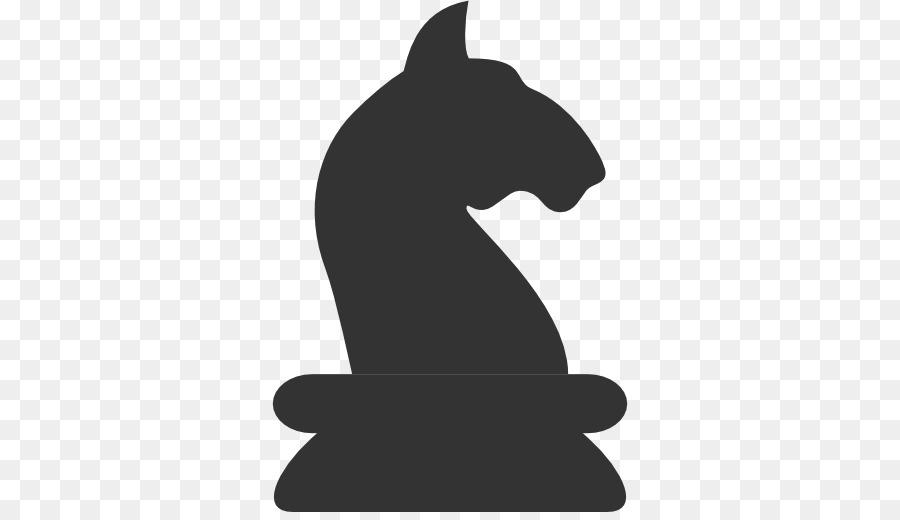

In [115]:
img = dataset["train"][0]["image"]
img


In [116]:
import numpy as np
np.array(img).shape


(520, 900, 3)

In [117]:
i2 = img.convert("RGB")
np.array(i2).shape

(520, 900, 3)

In [81]:
#### Implement the preprocess_function to convert images to RGB and tokenize them

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

result = preprocess_function(dataset["train"][:2])
print(list(result.keys()))
result["pixel_values"]

['pixel_values', 'label']


tensor([[[[ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          [ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          [ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          ...,
          [ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000]],

         [[ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          [ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          [ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          ...,
          [ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000]],

         [[ 0.7725,  0.7725,  0.7725,  ..., -0.1922, -0.1922, -0.1922],
          [ 0.7725,  0.7725,  

In [82]:
#### Process the entire dataset using the preprocess_function
prepared_dataset = dataset.map(preprocess_function, batched=True)
prepared_dataset

Map:   0%|          | 0/444 [00:00<?, ? examples/s]

Map:   0%|          | 0/56 [00:00<?, ? examples/s]

Map:   0%|          | 0/56 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 444
    })
    validation: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 56
    })
    test: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 56
    })
})

In [83]:
dataset["train"][40]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=550x550>,
 'label': 0}

In [85]:
prepared_dataset["train"][400]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=133x225>,
 'label': 1,
 'pixel_values': [[[0.03529411926865578,
    0.019607843831181526,
    0.003921568859368563,
    -0.003921568859368563,
    -0.0117647061124444,
    -0.019607843831181526,
    -0.027450980618596077,
    -0.04313725605607033,
    -0.04313725605607033,
    -0.04313725605607033,
    -0.05098039284348488,
    -0.05098039284348488,
    -0.04313725605607033,
    -0.03529411926865578,
    -0.03529411926865578,
    -0.027450980618596077,
    -0.0117647061124444,
    0.003921568859368563,
    0.019607843831181526,
    0.03529411926865578,
    0.05098039284348488,
    0.06666667014360428,
    0.09019608050584793,
    0.11372549086809158,
    0.12941177189350128,
    0.14509804546833038,
    0.16078431904315948,
    0.16862745583057404,
    0.1764705926179886,
    0.18431372940540314,
    0.1921568661928177,
    0.20000000298023224,
    0.21568627655506134,
    0.2235294133424759,
    0.23137255012989044,
    

In [86]:
##### Step 6: Define the training arguments and Trainer
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="../../data/results",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    dataloader_pin_memory=False # silence the warning on MacOS Apple Silicon
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
)


In [87]:
##### Step 7: Inference / Predict using the test set
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics

{'test_loss': 1.8139344453811646,
 'test_model_preparation_time': 0.0015,
 'test_runtime': 1.9235,
 'test_samples_per_second': 29.114,
 'test_steps_per_second': 2.08}

In [88]:
predictions.predictions

array([[-6.15293384e-02,  1.80742621e-01,  5.11383861e-02,
         1.33401141e-01,  1.27147347e-01, -1.76686212e-01],
       [-3.01094316e-02,  1.04095843e-02, -8.44080001e-02,
         1.41983628e-01,  6.41889200e-02,  2.26866920e-02],
       [-1.93463683e-01,  6.50667846e-02,  5.70414215e-02,
         6.22068942e-02,  3.57539207e-03,  4.35747430e-02],
       [-3.94200869e-02, -1.64743334e-01, -3.58133912e-02,
         4.56677936e-02,  1.44215211e-01,  4.98543493e-03],
       [-9.22235921e-02,  1.10604949e-02, -3.96690331e-03,
        -1.43775463e-01,  1.29040182e-02, -2.51853950e-02],
       [-1.76291496e-01,  9.03507918e-02,  1.03094801e-02,
        -7.64100477e-02,  9.50259417e-02, -7.81744272e-02],
       [-1.65185720e-01,  7.80069605e-02,  5.56681380e-02,
        -2.01333910e-02,  1.50331156e-02,  4.92908582e-02],
       [-1.03254877e-01,  3.23944539e-02,  3.38058732e-02,
        -1.77066773e-02,  4.51957732e-02,  5.36924973e-02],
       [-1.37132317e-01,  9.38121900e-02,  8.097

In [89]:
##### Step 8: Evaluate the model performance
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")


[2 2 4 1 3 3 3 5 3 3 3 4 3 3 5 3 3 3 0 4 1 0 5 4 2 0 4 5 2 5 3 0 0 1 2 3 3
 3 5 3 3 5 2 2 4 4 5 4 0 0 5 3 1 2 3 2]
[1 3 1 4 4 4 1 5 3 4 3 0 1 1 3 4 2 1 4 3 5 2 1 2 2 5 5 5 1 1 2 2 2 4 1 1 4
 2 3 4 2 5 1 1 4 2 5 5 4 4 1 5 5 4 2 3]


In [90]:

incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)


Incorrectly classified sample indices: [ 0  1  2  3  4  5  6  9 11 12 13 14 15 16 17 18 19 20 21 22 23 25 26 28
 29 30 31 32 33 34 35 36 37 38 39 40 42 43 45 47 48 49 50 51 52 53 54 55]
Predicted labels for incorrect samples: [1 3 1 4 4 4 1 4 0 1 1 3 4 2 1 4 3 5 2 1 2 5 5 1 1 2 2 2 4 1 1 4 2 3 4 2 1
 1 2 5 4 4 1 5 5 4 2 3]
True labels for incorrect samples: [2 2 4 1 3 3 3 3 4 3 3 5 3 3 3 0 4 1 0 5 4 0 4 2 5 3 0 0 1 2 3 3 3 5 3 3 2
 2 4 4 0 0 5 3 1 2 3 2]


In [91]:
incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

Predicted label names for incorrect samples: ['King', 'Pawn', 'King', 'Queen', 'Queen', 'Queen', 'King', 'Queen', 'Bishop', 'King', 'King', 'Pawn', 'Queen', 'Knight', 'King', 'Queen', 'Pawn', 'Rook', 'Knight', 'King', 'Knight', 'Rook', 'Rook', 'King', 'King', 'Knight', 'Knight', 'Knight', 'Queen', 'King', 'King', 'Queen', 'Knight', 'Pawn', 'Queen', 'Knight', 'King', 'King', 'Knight', 'Rook', 'Queen', 'Queen', 'King', 'Rook', 'Rook', 'Queen', 'Knight', 'Pawn']
True label names for incorrect samples: ['Knight', 'Knight', 'Queen', 'King', 'Pawn', 'Pawn', 'Pawn', 'Pawn', 'Queen', 'Pawn', 'Pawn', 'Rook', 'Pawn', 'Pawn', 'Pawn', 'Bishop', 'Queen', 'King', 'Bishop', 'Rook', 'Queen', 'Bishop', 'Queen', 'Knight', 'Rook', 'Pawn', 'Bishop', 'Bishop', 'King', 'Knight', 'Pawn', 'Pawn', 'Pawn', 'Rook', 'Pawn', 'Pawn', 'Knight', 'Knight', 'Queen', 'Queen', 'Bishop', 'Bishop', 'Rook', 'Pawn', 'King', 'Knight', 'Pawn', 'Knight']


In [ ]:
incorrect_samples = dataset["test"].select(incorrect_indices)
incorrect_samples

In [ ]:
!pip install seaborn 

In [ ]:
!pip install scikit-learn

In [ ]:
!pip install matplotlib

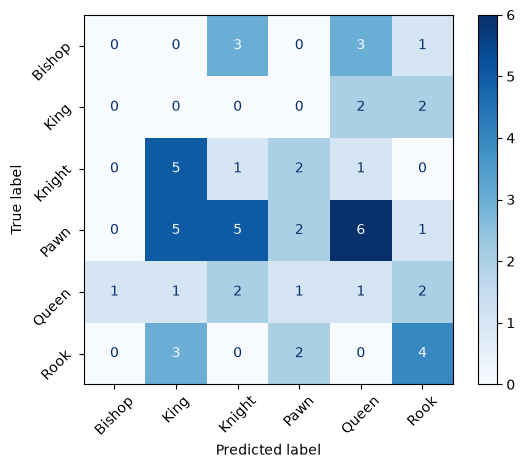

In [92]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = trainer.predict(prepared_dataset["test"])
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
disp.ax_.set_xticklabels(dataset["test"].features["label"].names, rotation=45)
disp.ax_.set_yticklabels(dataset["test"].features["label"].names, rotation=45)
plt.show()

#import seaborn as sns

#cm = confusion_matrix(true_labels, predicted_labels)
#label_names = dataset["train"].features["label"].names

#plt.figure(figsize=(10, 8))
#sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#            xticklabels=label_names, yticklabels=label_names)

#plt.xlabel('Predicted Label')   
#plt.ylabel('True Label')
#plt.title('Confusion Matrix')
#plt.show()

In [ ]:
import sklearn
sklearn.__version__

### Fine-tuning this model

In [ ]:
import evaluate


In [93]:
##### Define the evaluation metric
import numpy as np
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)

In [94]:
##### Training the model with new dataset (fine-tuning)
import os
#os.environ["TENSORBOAD_LOGGING_DIR"] = "../../data/logs/vit-finetuned-chessman2"

from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(
    output_dir="../../data/models/vit-finetuned-chessman-oct14_2",
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    #logging_dir="../../data/logs/vit-finetuned-chessman-oct14_1",
    logging_strategy="epoch",

    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    push_to_hub=False,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.01
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.743848,1.636526,0.500000
2,1.535074,1.428596,0.607143
3,1.289682,1.198220,0.625000
4,1.041779,0.989234,0.767857
5,0.822993,0.815183,0.839286
6,0.634761,0.663320,0.875000
7,0.477470,0.571574,0.875000
8,0.356504,0.497025,0.875000
9,0.260144,0.438363,0.892857
10,0.195420,0.400944,0.892857


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=336, training_loss=0.7197260281869343, metrics={'train_runtime': 179.2582, 'train_samples_per_second': 29.722, 'train_steps_per_second': 1.874, 'total_flos': 4.128921226218701e+17, 'train_loss': 0.7197260281869343, 'epoch': 12.0})

In [95]:

trainer.save_model("../../data/models/vit-finetuned-chessman7")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [96]:
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


{'test_loss': 0.3458937108516693,
 'test_accuracy': 0.875,
 'test_runtime': 1.4597,
 'test_samples_per_second': 38.363,
 'test_steps_per_second': 2.74}

In [97]:
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

[2 2 4 1 3 3 3 5 3 3 3 4 3 3 5 3 3 3 0 4 1 0 5 4 2 0 4 5 2 5 3 0 0 1 2 3 3
 3 5 3 3 5 2 2 4 4 5 4 0 0 5 3 1 2 3 2]
[2 2 4 1 3 3 3 5 3 3 3 4 3 3 5 3 3 3 0 4 1 0 5 0 2 0 1 5 2 5 3 0 0 1 2 3 3
 3 4 3 3 3 2 2 1 4 5 5 0 1 5 3 1 2 3 2]


In [98]:
incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

true_label_names = dataset["test"].features["label"]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)

incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

Incorrectly classified sample indices: [23 26 38 41 44 47 49]
Predicted labels for incorrect samples: [0 1 4 3 1 5 1]
True labels for incorrect samples: [4 4 5 5 4 4 0]
Predicted label names for incorrect samples: ['Bishop', 'King', 'Queen', 'Pawn', 'King', 'Rook', 'King']
True label names for incorrect samples: ['Queen', 'Queen', 'Rook', 'Rook', 'Queen', 'Queen', 'Bishop']


In [99]:
incorrect_samples = dataset["test"].select(incorrect_indices)
incorrect_samples

Dataset({
    features: ['image', 'label'],
    num_rows: 7
})

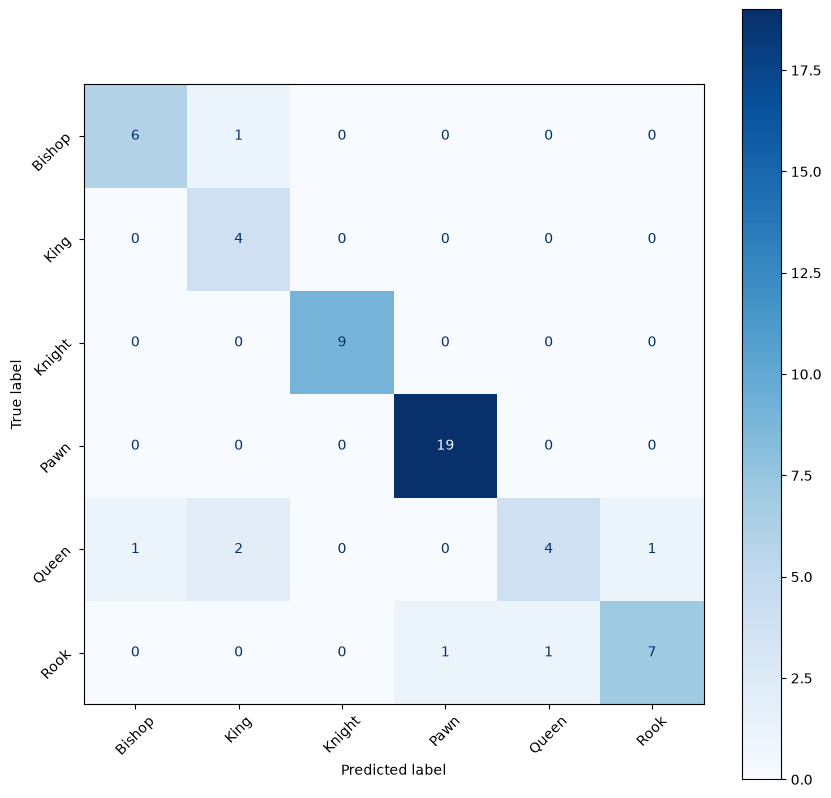

In [100]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def plot_confusion_matrix(labels, pred_labels):

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(1, 1, 1)
    cm = confusion_matrix(labels, pred_labels)
    cm = ConfusionMatrixDisplay(cm, display_labels=range(6))
    cm.plot(values_format='d', cmap='Blues', ax=ax)
    cm.ax_.set_xticklabels(dataset["test"].features["label"].names, rotation=45)
    cm.ax_.set_yticklabels(dataset["test"].features["label"].names, rotation=45)
    plt.show()

plot_confusion_matrix(true_labels, predicted_labels)

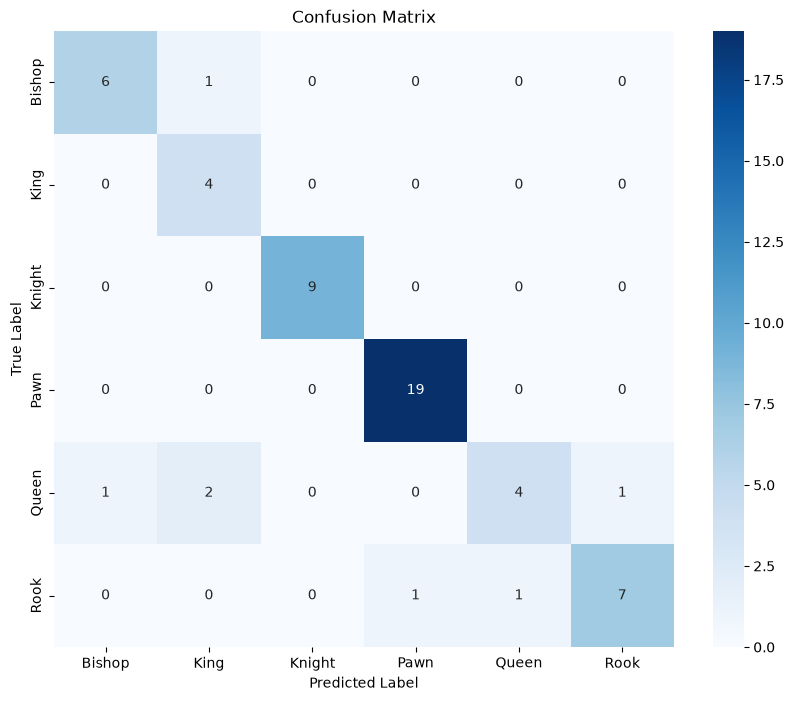

In [101]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_labels, predicted_labels)
label_names = dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
trainer.save_model("../../data/models/vit-finetuned-chessman-final2")

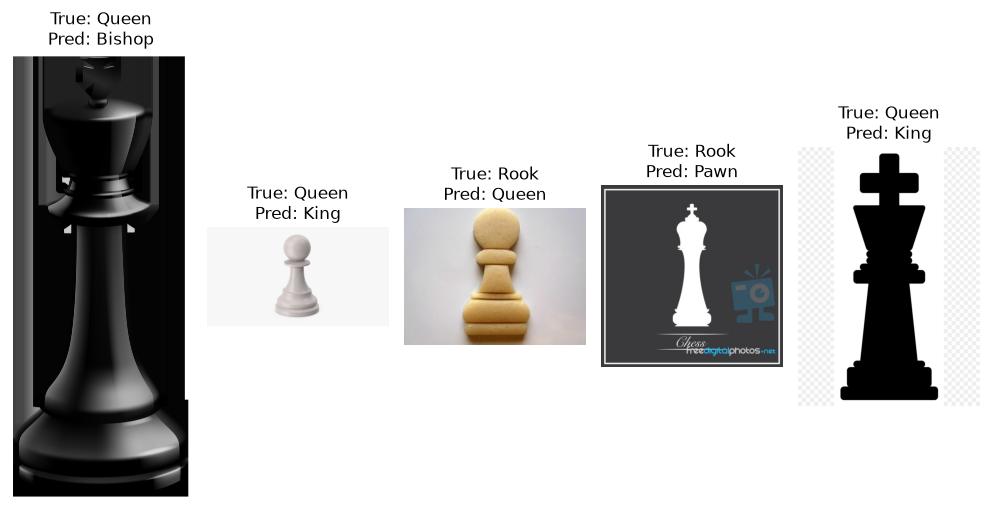

In [102]:
import matplotlib.pyplot as plt

num_plots = min(5, len(incorrect_samples))

plt.figure(figsize=(10, 5))
for i in range(num_plots):
    idx = incorrect_indices[i]
    # Assuming the dataset returns a dictionary with 'image' and 'label'
    sample = test_dataset[idx] 
    image = sample['image'] 
    
    plt.subplot(1, num_plots, i + 1)
    plt.imshow(image)
    plt.title(f"True: {true_label_names_incorrect[i]}\nPred: {incorrect_label_names[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

---

### Exercise: Try fine-tuning ViT model for fatigue dataset (from Kaggle)
The link to the dataset: https://www.kaggle.com/datasets/rihabkaci99/fatigue-dataset/

Try using `mo-thecreator/vit-Facial-Expression-Recognition` and `trpakov/vit-face-expression` models 
from HuggingFace as the initial checkpoint

In [ ]:
ls ../data/Human_Face_Expression_Fatigue/

In [ ]:
#### Step 1: Load your custom dataset
from datasets import load_dataset
dataset = load_dataset("../data/Human_Face_Expression_Fatigue")
dataset

In [ ]:
#### Step 2: Split the dataset into training, validation and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_test["train"]
print(train_dataset)

test_val = train_test["test"].train_test_split(test_size=0.5)
val_dataset = test_val["train"]
test_dataset = test_val["test"]

from datasets import DatasetDict
dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
})
dataset

num_classes = dataset["train"].features["label"].num_classes
num_classes


In [ ]:
#### Step 3: Use a pretrained model
checkpoint = "mo-thecreator/vit-Facial-Expression-Recognition"
model = AutoModelForImageClassification.from_pretrained(
    checkpoint, 
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)

In [ ]:
##### Step 4: Preprocess the images suited to the model
from transformers import AutoImageProcessor
image_processor = AutoImageProcessor.from_pretrained(checkpoint, use_fast=True)

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

prepared_dataset = dataset.map(preprocess_function, batched=True)
prepared_dataset

In [ ]:
##### Step 5: Setup evaluation metrics and callbacks (optional)
##### Define the evaluation metric
import numpy as np
import evaluate

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)

In [ ]:
##### Step 6: Initialize the Trainer and define the training arguments, train the model
import os
os.environ["TENSORBOARD_LOGGING_DIR"] = "../data/logs/vit-facial-expression-fatigue"

from transformers import TrainingArguments, Trainer
training_args = TrainingArguments(
    output_dir="../data/vit-facial-expression-fatigue",
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    #logging_dir="../../data/logs/vit-facial-expression-fatigue",
    logging_strategy="epoch",

    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    push_to_hub=False,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.01
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)
trainer.train()

In [ ]:
##### Step 7: Inference / Predict using the test set
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


In [ ]:
##### Step 8: Evaluate the model performance with test set and visualize the results

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

cm = confusion_matrix(true_labels, predicted_labels)
label_names = prepared_dataset["train"].features["label"].names

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
#### Step 9: Save the fine-tuned model
trainer.save_model("../data/models/vit-finetuned-human-face-expression-fatigue")

In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir ../data/logs/vit-facial-expression-fatigue

---

In [ ]:
g = model.parameters()

In [ ]:
model.get_memory_footprint() / (1024 * 1024)

In [ ]:
total = 0
for p in model.parameters():
    total += p.numel()

total / (1000 * 1000)

---